# Lab 8: Semi-Supervised Learning with Self-Training

MLPR, Semester 4. Only 200 of 2,200 points have a cancer-stage label. A k-NN classifier wrapped in scikit-learn's `SelfTrainingClassifier` labels the 2,000 unlabelled points iteratively. Its predictions are then compared with the true stages.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.semi_supervised import SelfTrainingClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, balanced_accuracy_score

df = pd.read_csv("data/data.csv")
labeled = df[["Clump thickness", "No of week", "Cancer stage"]].dropna()
print(f"labelled points: {len(labeled)}, unlabelled points: {len(df)}")

X_labeled, y_labeled = labeled[["Clump thickness", "No of week"]].values, labeled["Cancer stage"].values
X_unlabeled, y_true = df[["Clump thickness_new", "No of week_new"]].values, df["True cancer stage"].values

model = SelfTrainingClassifier(KNeighborsClassifier(n_neighbors=5)).fit(
    np.vstack((X_labeled, X_unlabeled)), np.hstack((y_labeled, np.full(len(X_unlabeled), -1))))
y_pred = model.predict(X_unlabeled)

print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_true, y_pred):.4f}\n")
print(classification_report(y_true, y_pred))

labelled points: 200, unlabelled points: 2000


Accuracy: 0.8915
Balanced accuracy: 0.8915

              precision    recall  f1-score   support

           1       0.71      0.98      0.82       500
           2       0.96      0.64      0.77       500
           3       1.00      0.96      0.98       500
           4       0.99      1.00      1.00       500

    accuracy                           0.89      2000
   macro avg       0.92      0.89      0.89      2000
weighted avg       0.92      0.89      0.89      2000



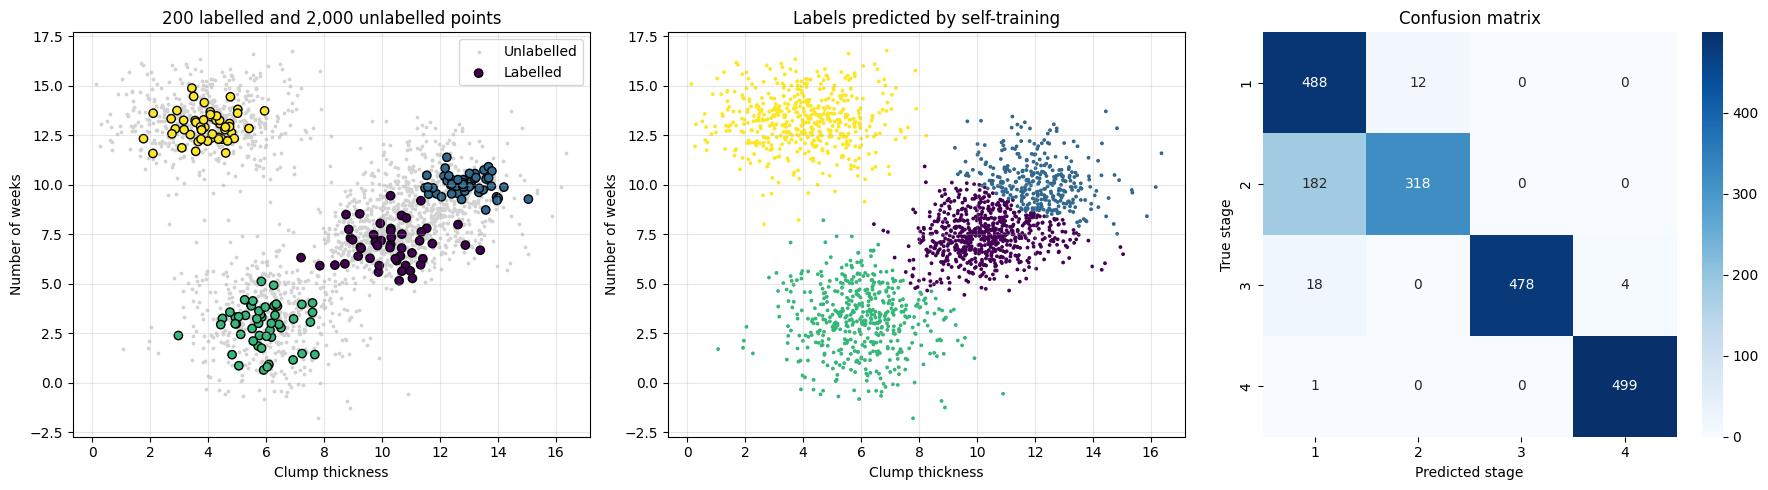

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(df["Clump thickness_new"], df["No of week_new"], color="lightgrey", s=3, label="Unlabelled")
sc = axes[0].scatter(X_labeled[:, 0], X_labeled[:, 1], c=y_labeled, cmap="viridis", edgecolors="k", label="Labelled")
axes[0].set_title("200 labelled and 2,000 unlabelled points"); axes[0].legend()
axes[1].scatter(X_unlabeled[:, 0], X_unlabeled[:, 1], c=y_pred, cmap="viridis", s=3)
axes[1].set_title("Labels predicted by self-training")
for ax in axes[:2]:
    ax.set_xlabel("Clump thickness"); ax.set_ylabel("Number of weeks"); ax.grid(alpha=0.3)
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=np.unique(y_true), yticklabels=np.unique(y_true), ax=axes[2])
axes[2].set_xlabel("Predicted stage"); axes[2].set_ylabel("True stage"); axes[2].set_title("Confusion matrix")
plt.tight_layout()
plt.savefig("images/lab08_self_training.png")
plt.show()

## Report

1. **Applications:** spam filtering (few emails labelled, many unlabelled), customer segmentation from purchase histories, and image tagging (for example recognising people in photos) where labelling is expensive.
2. **Assumptions:** continuity (nearby points share labels), cluster (points in the same cluster share labels) and manifold (high-dimensional data lies on a lower-dimensional surface).
3. **Why they matter:** continuity gives smooth decision boundaries. The cluster assumption lets a few labels spread to whole clusters. The manifold assumption makes distances meaningful in high dimensions.
4. **Co-training vs self-training:** self-training uses one model that labels its own most confident unlabelled points and retrains. Co-training trains two models on different feature views that label data for each other. Co-training often performs better when two independent, sufficient views exist, because the models correct each other's mistakes.
5. **Evaluating while training:** hold out a labelled validation set, and track accuracy, balanced accuracy, precision, recall, F1 and the confusion matrix as pseudo-labels are added.